# Imports

## Import the folder for compatibility (if running local)

In [ ]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [18]:
import time
from typing import Optional, Tuple, Dict, Any, List

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
#from river.ensemble import BaggingRegressor, SRPRegressor
from river.tree import HoeffdingTreeRegressor, HoeffdingAdaptiveTreeRegressor
#from river.drift.binary import DDM, EDDM
from src.bagging import ARFRegressorFODT
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.trees import fastodt
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict
from src.evaluation.baseline import PreviousValueRegressor

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [ ]:
# check you data dir and file prefixes
data_dir = '../../data/first_batch'

## Pick the hourly or 5-min granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity
- WFV, train+=28 (train set increasing), validation=28, 5-min granularity

In [20]:
HOURLY = True
DATA_FREQUENCY = 'H' if HOURLY else '5min'

In [27]:
# Measure loading time
start_time = time.time()

# Load data
if HOURLY:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_hourly_wfv', use_numpy=True)
    features = ['time', 'device_id', 'hour', 'weekday', 'month', 
                 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
                 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
                 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
                 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
                 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
                 'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
                 'L3_act_power_lag_1h', 'L3_act_power_lag_24h', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
                 'L3_current_lag_1h', 'L3_current_lag_24h', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
                 'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
                 'grid_freq_lag_1h', 'grid_freq_lag_24h', 
                 'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
                 'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
                 'powerfactor3_lag_1h', 'powerfactor3_lag_24h']
else:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='8_dev_5_min_wfv', use_numpy=True)
    # copy features from dataloader printouts
    features = []

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[ERROR] File Incremental-Learning-MycroftMinds\datairst_batch\dev_4_hourly_wfv_train.npz does not exist.


TypeError: object of type 'NoneType' has no len()

## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 7 splits
Validation data: 7 splits
First train split shape: X=(649, 43), y=(649,)
First valid split shape: X=(672, 43), y=(672,)

Memory usage:
Train: 6.26 MB
Valid: 1.41 MB
Test: 0.41 MB
Total: 8.08 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

## Hourly granularity

### Baseline model (predict previous value)

In [7]:
update_freq = "1H"
baseline = PreviousValueRegressor()

In [8]:
baseline_train_period_predictions, baseline_valid_period_predictions,\
baseline_train_period_metrics, baseline_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=baseline,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2535
	MAE: 0.1477
	MAPE: 17.4044%

Directional Metrics:
	Directional Accuracy: 36.0656%
	First-Diff Correlation: -0.0202

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3479
	MAE: 0.

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2578
	MAE: 0.1454
	MAPE: 23.4458%

Directional Metrics:
	Directional Accuracy: 38.3010%
	First-Diff Correlation: 0.2243

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3271
	MAE: 0.1

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2448
	MAE: 0.1448
	MAPE: 31.0642%

Directional Metrics:
	Directional Accuracy: 37.4069%
	First-Diff Correlation: -0.0210

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2440
	MAE: 0.

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1543
	MAE: 0.0696
	MAPE: 12.5644%

Directional Metrics:
	Directional Accuracy: 40.1274%
	First-Diff Correlation: 0.4616

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.7500
		Recall: 1.0000
		F1: 0.8571
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1261
	MAE: 0.0

#### Results

In [9]:
print("\n\nValid period metrics:")
baseline_all_time_valid_metrics = all_time_aggregation_metrics(baseline_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2280 ± 0.0407
	MAE: 0.1290 ± 0.0296
	MAPE: 23.9570% ± 7.3836%

	Directional Metrics:
		Directional Accuracy: 39.3923% ± 4.6442%
		First-Diff Correlation: 0.1838 ± 0.1970

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8571 ± 0.3499
		Spike Recall: 0.8571 ± 0.3499
		Spike F1: 0.8571 ± 0.3499
		Drop Precision: 0.8139 ± 0.3429
		Drop Recall: 0.8571 ± 0.3499
		Drop F1: 0.8329 ± 0.3434
Daily Metrics:
	RMSE: 0.2624 ± 0.0673
	MAE: 0.1164 ± 0.0326
	MAPE: 1.3658% ± 0.2072%

	Directional Metrics:
		Directional Accuracy: 95.9184% ± 3.5348%
		First-Diff Correlation: 0.9995 ± 0.0003

	Immediate Detection (delta=0):


#### Validation plots

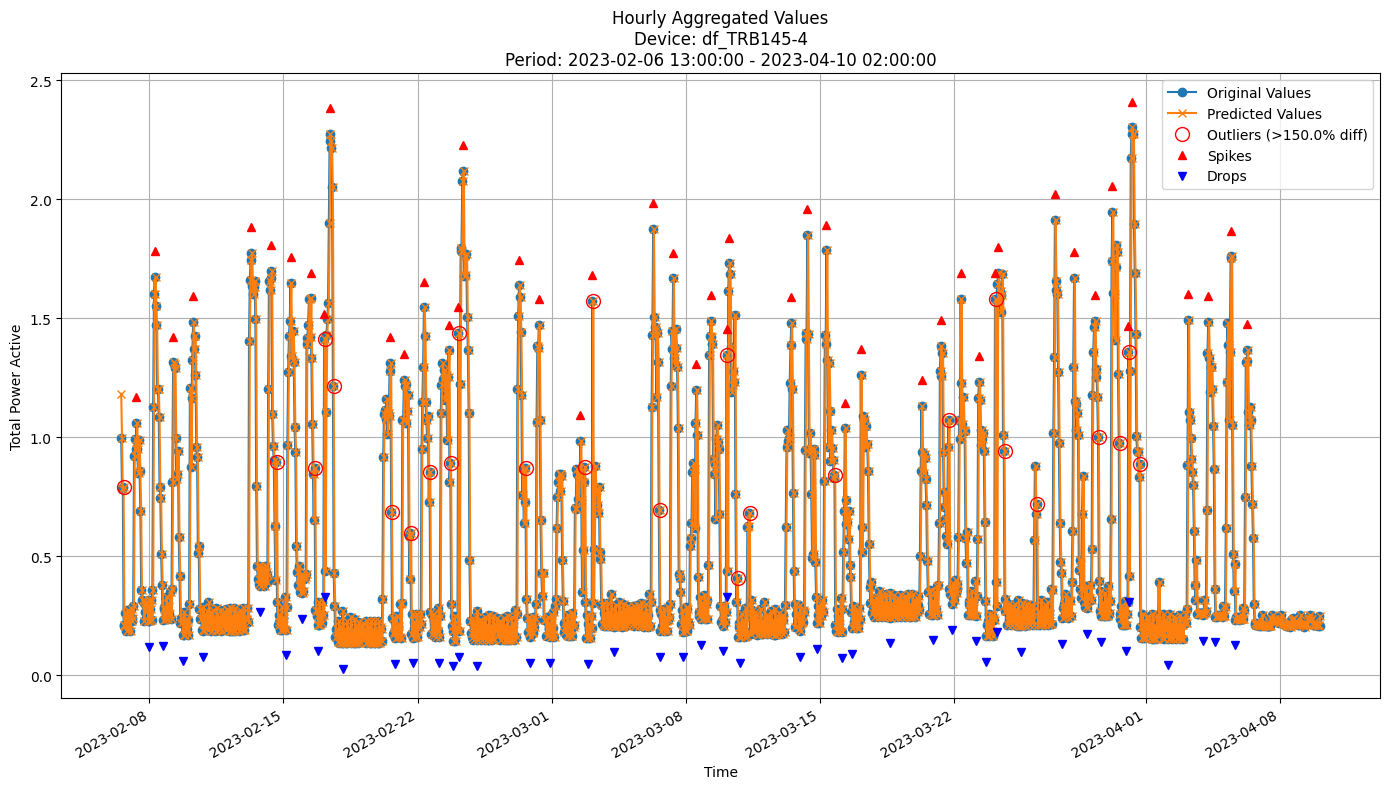


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2328
MAE: 0.1326
MAPE: 29.8567%

Directional Metrics:
Directional Accuracy: 36.8421%
First-Diff Correlation: -0.0120

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.9787
  Recall: 1.0000
  F1 Score: 0.9892


In [10]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in baseline_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, baseline_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, baseline_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [ ]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.03,
    subsample=0.8,
    max_depth=10,
    random_state=42)

# Results from hyperparam. tuning
# RMSE (best: 0.230)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 3, 'subsample': 0.8, 'random_state': 42}
# MAE (best: 0.143)
#     Parameters: {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 1.0, 'random_state': 42}
# MAPE (best: 28.070%)
#     Parameters: {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 1.0, 'random_state': 42}
# DIR_ACCURACY (best: 62.673%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 12, 'subsample': 0.8, 'random_state': 42}
# FIRST_DIFF_CORR (best: 42.984%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 0.6, 'random_state': 42}
# SPIKES_F1 (best: 20.873%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 3, 'subsample': 0.6, 'random_state': 42}
# DROPS_F1 (best: 15.373%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.15, 'max_depth': 15, 'subsample': 0.8, 'random_state': 42}

In [12]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=gbdt, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00

Time: 1.33 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-10-17 13:00:00 to 2022-10-31 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-10-31 13:00:00

Time: 2.02 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-10-31 14:00:00 to 2022-11-14 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3575
	MAE: 0.2497
	MAPE: 31.6904%

Directional Metrics:
	Directional Accuracy: 56.0358%
	First-Diff Correlation: 0.2208

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00

Time: 2.73 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-11-14 13:00:00 to 2022-11-28 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-28 13:00:00

Time: 3.44 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-11-28 14:00:00 to 2022-12-12 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3039
	MAE: 0.2046
	MAPE: 40.8759%

Directional Metrics:
	Directional Accuracy: 59.1654%
	First-Diff Correlation: 0.3749

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00

Time: 8.59 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-03-06 13:00:00 to 2023-03-20 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-20 13:00:00

Time: 9.60 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2023-03-20 14:00:00 to 2023-04-03 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2344
	MAE: 0.1534
	MAPE: 35.1393%

Directional Metrics:
	Directional Accuracy: 53.3532%
	First-Diff Correlation: 0.3064

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1250
		Recall: 0.1000
		F1: 0.1111


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00

Time: 10.47 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-04-03 13:00:00 to 2023-04-10 02:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1705
	MAE: 0.1065
	MAPE: 29.9095%

Directional Metrics:
	Directional Accuracy: 59.2357%
	First-Diff Correlation: 0.3266

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2500
		Recall: 0.2500
		F1: 0.2500
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7500
		Recall: 0.7500
		F1: 0.7500
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------

#### Results

In [13]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.2486 ± 0.0612
# 	MAE: 0.1594 ± 0.0516
# 	MAPE: 33.4958% ± 5.3587%

# 	Directional Metrics:
# 		Directional Accuracy: 62.4754% ± 7.1041%
# 		First-Diff Correlation: 0.3821 ± 0.0970

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.1544 ± 0.1193
# 		Spike Recall: 0.1617 ± 0.1297
# 		Spike F1: 0.1577 ± 0.1238
# 		Drop Precision: 0.1459 ± 0.0857
# 		Drop Recall: 0.1534 ± 0.0909
# 		Drop F1: 0.1493 ± 0.0879

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4691 ± 0.2714
# 		Spike Recall: 0.4908 ± 0.2907
# 		Spike F1: 0.4788 ± 0.2795
# 		Drop Precision: 0.2117 ± 0.1062
# 		Drop Recall: 0.2201 ± 0.1161
# 		Drop F1: 0.2153 ± 0.1100



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0497 ± 0.0106
	MAE: 0.0333 ± 0.0046
	MAPE: 7.4065% ± 1.1843%

	Directional Metrics:
		Directional Accuracy: 89.1446% ± 1.3532%
		First-Diff Correlation: 0.9760 ± 0.0145

	Immediate Detection (delta=0):
		Spike Precision: 0.4654 ± 0.4091
		Spike Recall: 0.4867 ± 0.4246
		Spike F1: 0.4757 ± 0.4165
		Drop Precision: 0.1472 ± 0.1319
		Drop Recall: 0.1546 ± 0.1384
		Drop F1: 0.1508 ± 0.1350

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5121 ± 0.4470
		Spike Recall: 0.5361 ± 0.4656
		Spike F1: 0.5237 ± 0.4558
		Drop Precision: 0.1631 ± 0.1518
		Drop Recall: 0.1705 ± 0.1567
		Drop F1: 0.1666 ± 0.1541
Daily Metrics:
	RMSE: 0.4566 ± 0.0575
	MAE: 0.3764 ± 0.0431
	MAPE: 3.4611% ± 0.3684%

	Directional Metrics:
		Directional Accuracy: 93.3766% ± 1.6407%
		First-Diff Correlation: 0.9995 ± 0.0003

	Immediate Detection (delta=0):
	

#### Feature importance
[WiP] Right now only for the last split and last device

In [14]:
feat_imps = sorted(
    zip(features[2:], gbdt.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', np.float64(0.5531829517537102)),
 ('L2_act_power_lag_1h', np.float64(0.07891330800039476)),
 ('hour', np.float64(0.07832269865487354)),
 ('L2_current_lag_1h', np.float64(0.05595649466475443)),
 ('L3_react_power_lag_1h', np.float64(0.04154862662622708)),
 ('month', np.float64(0.013196429149711796)),
 ('L1_act_power_lag_1h', np.float64(0.011640492147334635)),
 ('L2_app_power_lag_1h', np.float64(0.010445078743705958)),
 ('L1_react_power_lag_24h', np.float64(0.010338615524865489)),
 ('powerfactor3_lag_1h', np.float64(0.009574609878353792)),
 ('grid_freq_lag_1h', np.float64(0.008365237194251272)),
 ('L3_react_power_lag_24h', np.float64(0.007908025282131134)),
 ('L3_act_power_lag_1h', np.float64(0.007307952132196116)),
 ('powerfactor1_lag_1h', np.float64(0.006540603057063766)),
 ('L2_act_power_lag_24h', np.float64(0.0064285377110188426)),
 ('grid_freq_lag_24h', np.float64(0.0061780235094540115)),
 ('powerfactor2_lag_24h', np.float64(0.0061596331313278855)),
 ('powerfac

#### Training plots

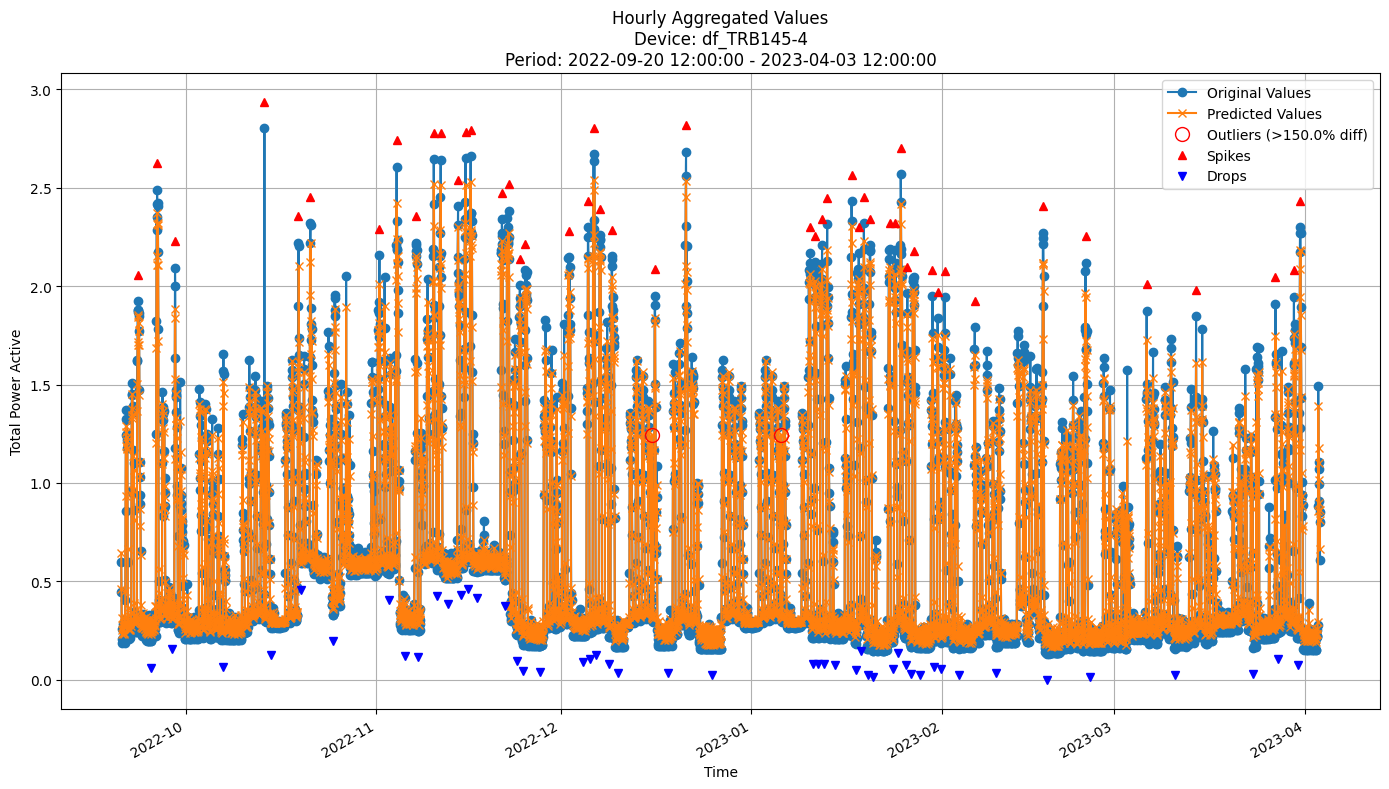


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0606
MAE: 0.0395
MAPE: 9.2928%

Directional Metrics:
Directional Accuracy: 86.6880%
First-Diff Correlation: 0.9631

Immediate Detection (delta=0):
Spikes:
  Precision: 0.6852
  Recall: 0.7551
  F1 Score: 0.7184
Drops:
  Precision: 0.2642
  Recall: 0.2917
  F1 Score: 0.2772

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7963
  Recall: 0.8776
  F1 Score: 0.8350
Drops:
  Precision: 0.2642
  Recall: 0.2917
  F1 Score: 0.2772


In [15]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

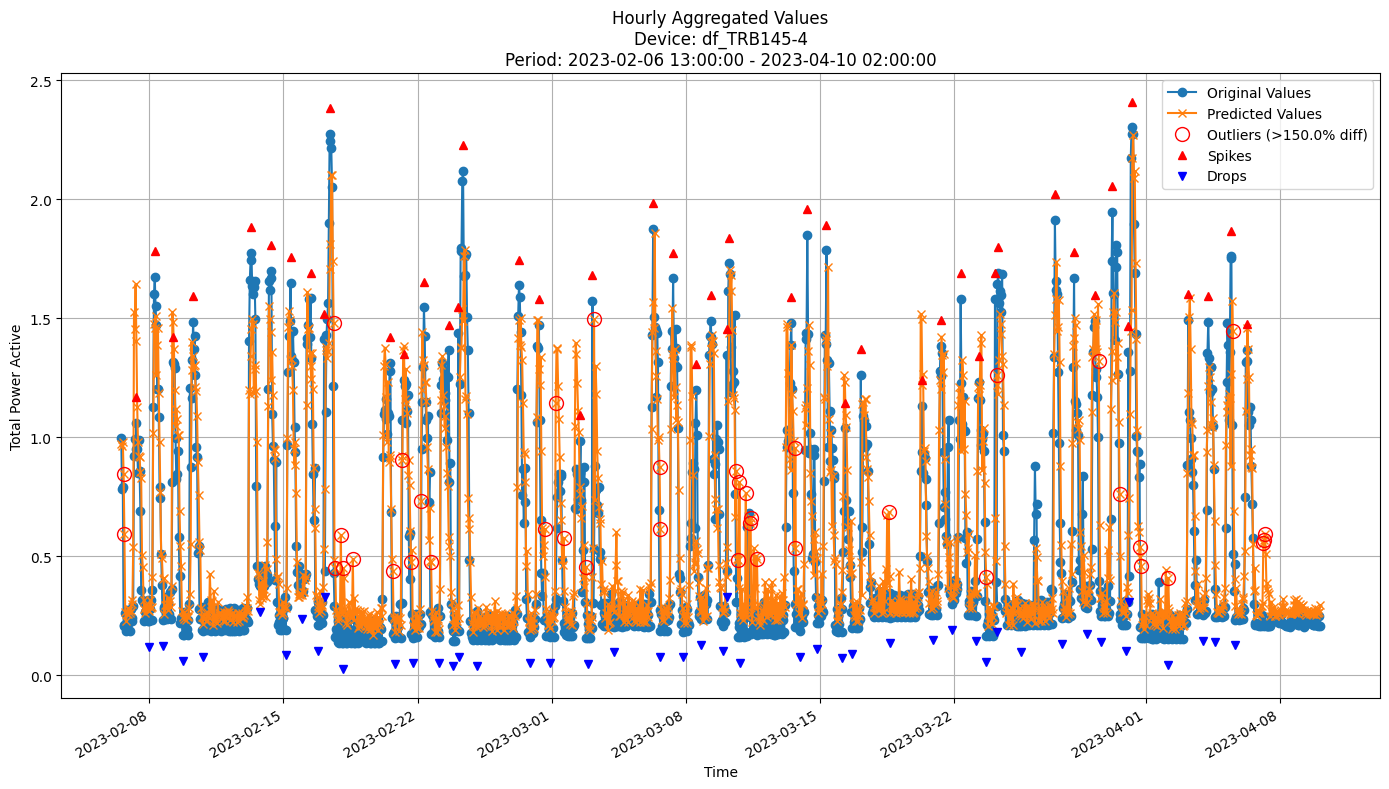


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2195
MAE: 0.1398
MAPE: 33.6987%

Directional Metrics:
Directional Accuracy: 59.5603%
First-Diff Correlation: 0.3785

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0476
  Recall: 0.0426
  F1 Score: 0.0449
Drops:
  Precision: 0.1463
  Recall: 0.1304
  F1 Score: 0.1379

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3571
  Recall: 0.3191
  F1 Score: 0.3371
Drops:
  Precision: 0.1707
  Recall: 0.1522
  F1 Score: 0.1609


In [16]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# 0.22, 0.15, 39.79, 60.39%, 0.39

### Random Forest model

In [ ]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor(
    n_estimators=100, 
    max_depth=10,
    max_features='sqrt',
    random_state=42, 
    n_jobs=-1)

# Results from hyperparam. tuning
# BEST RMSE: 0.230
#    Best Parameters: {'n_estimators': 150, 'max_depth': 15, 'max_features': 0.5, 'random_state': 42, 'n_jobs': -1}
# BEST MAE: 0.140
#    Best Parameters: {'n_estimators': 50, 'max_depth': 7, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST MAPE: 27.282%
#    Best Parameters: {'n_estimators': 50, 'max_depth': 7, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST DIR_ACCURACY: 63.559%
#    Best Parameters: {'n_estimators': 200, 'max_depth': 20, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST FIRST_DIFF_CORR: 44.507%
#    Best Parameters: {'n_estimators': 300, 'max_depth': 5, 'max_features': 0.3, 'random_state': 42, 'n_jobs': -1}
# BEST SPIKES_F1: 20.414%
#    Best Parameters: {'n_estimators': 50, 'max_depth': 5, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST DROPS_F1: 14.260%
#    Best Parameters: {'n_estimators': 200, 'max_depth': 20, 'max_features': 0.3, 'random_state': 42, 'n_jobs': -1}

In [18]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=rf, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00

Time: 0.12 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-10-17 13:00:00 to 2022-10-31 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-10-31 13:00:00

Time: 0.13 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-10-31 14:00:00 to 2022-11-14 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2993
	MAE: 0.1853
	MAPE: 21.3879%

Directional Metrics:
	Directional Accuracy: 60.2086%
	First-Diff Correlation: 0.3247

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.3333
		Recall: 0.0909
		F1: 0.1429


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00

Time: 0.13 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-11-14 13:00:00 to 2022-11-28 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-28 13:00:00

Time: 0.13 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-11-28 14:00:00 to 2022-12-12 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2835
	MAE: 0.1840
	MAPE: 32.3479%

Directional Metrics:
	Directional Accuracy: 59.3145%
	First-Diff Correlation: 0.4329

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00

Time: 0.24 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-03-06 13:00:00 to 2023-03-20 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-20 13:00:00

Time: 0.20 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2023-03-20 14:00:00 to 2023-04-03 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2388
	MAE: 0.1581
	MAPE: 35.5592%

Directional Metrics:
	Directional Accuracy: 52.6080%
	First-Diff Correlation: 0.3214

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0833
		Recall: 0.0526
		F1: 0.0645
	Drops:
		Precision: 0.0833
		Recall: 0.0500
		F1: 0.0625


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00

Time: 0.22 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-04-03 13:00:00 to 2023-04-10 02:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1629
	MAE: 0.0982
	MAPE: 26.4494%

Directional Metrics:
	Directional Accuracy: 54.1401%
	First-Diff Correlation: 0.3509

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.6667
		Recall: 0.5000
		F1: 0.5714
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.7500
		F1: 0.8571
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
---------------------------------------

#### Results

In [19]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)

# Best values:
# Hourly Metrics:
# 	RMSE: 0.2221 ± 0.0148
# 	MAE: 0.1267 ± 0.0092
# 	MAPE: 22.1472% ± 2.0063%

# 	Directional Metrics:
# 		Directional Accuracy: 60.8511% ± 2.9815%
# 		First-Diff Correlation: 0.4859 ± 0.0565

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.2094 ± 0.0638
# 		Spike Recall: 0.1844 ± 0.0780
# 		Spike F1: 0.1927 ± 0.0741
# 		Drop Precision: 0.0547 ± 0.0125
# 		Drop Recall: 0.1408 ± 0.0536
# 		Drop F1: 0.0779 ± 0.0216

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4647 ± 0.0473
# 		Spike Recall: 0.3984 ± 0.1023
# 		Spike F1: 0.4191 ± 0.0799
# 		Drop Precision: 0.1104 ± 0.0172
# 		Drop Recall: 0.2821 ± 0.0884
# 		Drop F1: 0.1571 ± 0.0324



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1121 ± 0.0109
	MAE: 0.0657 ± 0.0060
	MAPE: 12.0611% ± 1.3292%

	Directional Metrics:
		Directional Accuracy: 78.0257% ± 1.7997%
		First-Diff Correlation: 0.8786 ± 0.0325

	Immediate Detection (delta=0):
		Spike Precision: 0.3766 ± 0.3610
		Spike Recall: 0.1696 ± 0.1838
		Spike F1: 0.2066 ± 0.1960
		Drop Precision: 0.0560 ± 0.0988
		Drop Recall: 0.0516 ± 0.0967
		Drop F1: 0.0535 ± 0.0974

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4531 ± 0.4038
		Spike Recall: 0.2264 ± 0.2608
		Spike F1: 0.2699 ± 0.2759
		Drop Precision: 0.0800 ± 0.1393
		Drop Recall: 0.0734 ± 0.1358
		Drop F1: 0.0762 ± 0.1371
Daily Metrics:
	RMSE: 0.8365 ± 0.0980
	MAE: 0.6152 ± 0.0705
	MAPE: 4.3721% ± 0.3706%

	Directional Metrics:
		Directional Accuracy: 90.6304% ± 3.7904%
		First-Diff Correlation: 0.9949 ± 0.0013

	Immediate Detection (delta=0):


#### Feature importance
[WiP] Right now only for the last split and last device

In [20]:
feat_imps = sorted(
    zip(features[2:], rf.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', np.float64(0.13092443502837656)),
 ('L3_act_power_lag_1h', np.float64(0.08706141874839739)),
 ('L1_act_power_lag_1h', np.float64(0.07877863378325366)),
 ('L3_app_power_lag_1h', np.float64(0.06553978046751792)),
 ('powerfactor3_lag_1h', np.float64(0.062356444548132516)),
 ('L2_act_power_lag_1h', np.float64(0.062135635279990574)),
 ('L2_current_lag_1h', np.float64(0.058767404985168616)),
 ('L1_app_power_lag_1h', np.float64(0.05610905975729264)),
 ('L3_current_lag_1h', np.float64(0.051358768289945234)),
 ('hour', np.float64(0.04538617571474976)),
 ('L2_app_power_lag_1h', np.float64(0.044414541617448886)),
 ('L2_react_power_lag_1h', np.float64(0.022629506250714703)),
 ('L2_current_lag_24h', np.float64(0.020464881900435522)),
 ('L1_react_power_lag_1h', np.float64(0.01985525501711811)),
 ('L2_app_power_lag_24h', np.float64(0.016238609827202)),
 ('L2_act_power_lag_24h', np.float64(0.01607517832982089)),
 ('L1_app_power_lag_24h', np.float64(0.014079573901327769)),
 ('L3_

#### Training plots
Plot only the last period of predictions

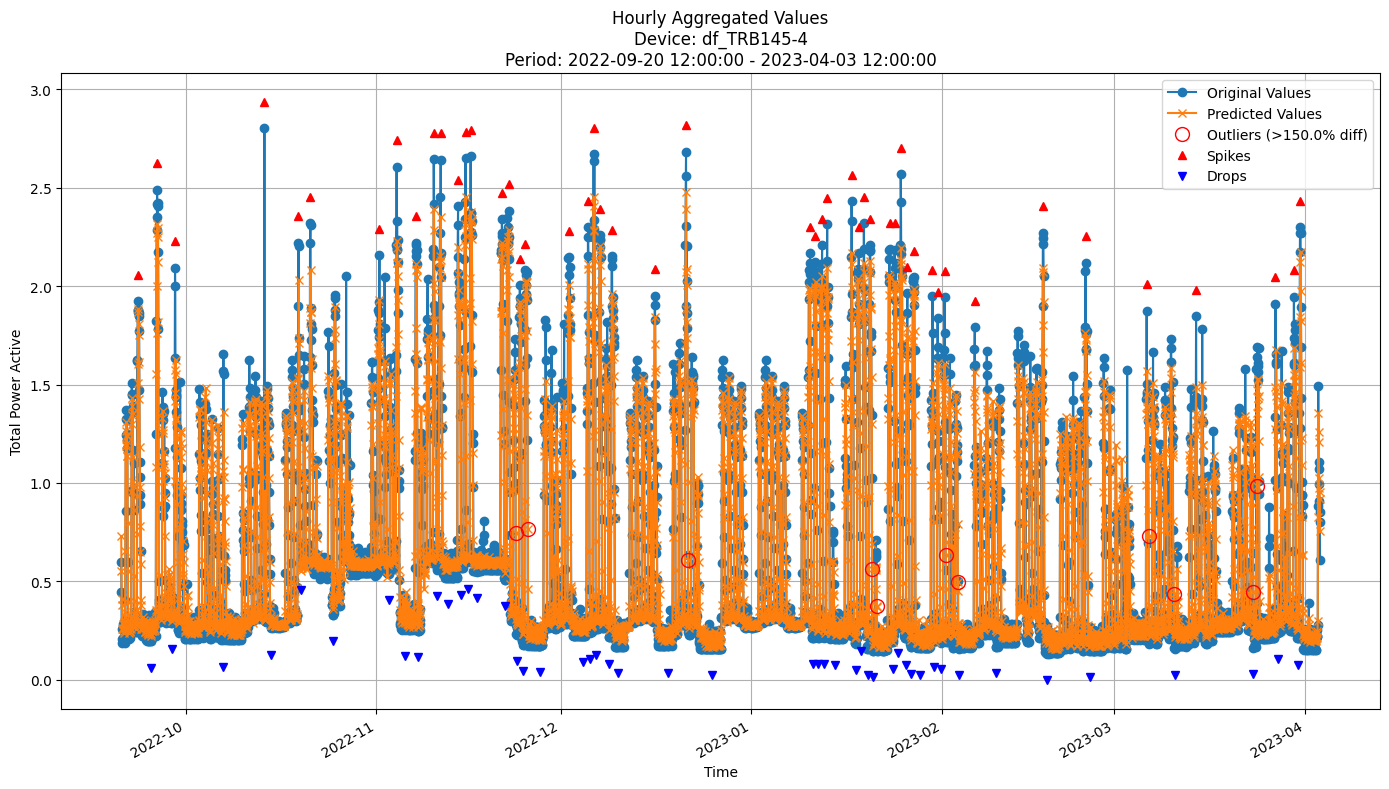


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1286
MAE: 0.0756
MAPE: 14.6978%

Directional Metrics:
Directional Accuracy: 75.1923%
First-Diff Correlation: 0.8301

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5000
  Recall: 0.3673
  F1 Score: 0.4235
Drops:
  Precision: 0.1143
  Recall: 0.0833
  F1 Score: 0.0964

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7778
  Recall: 0.5714
  F1 Score: 0.6588
Drops:
  Precision: 0.1714
  Recall: 0.1250
  F1 Score: 0.1446


In [21]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

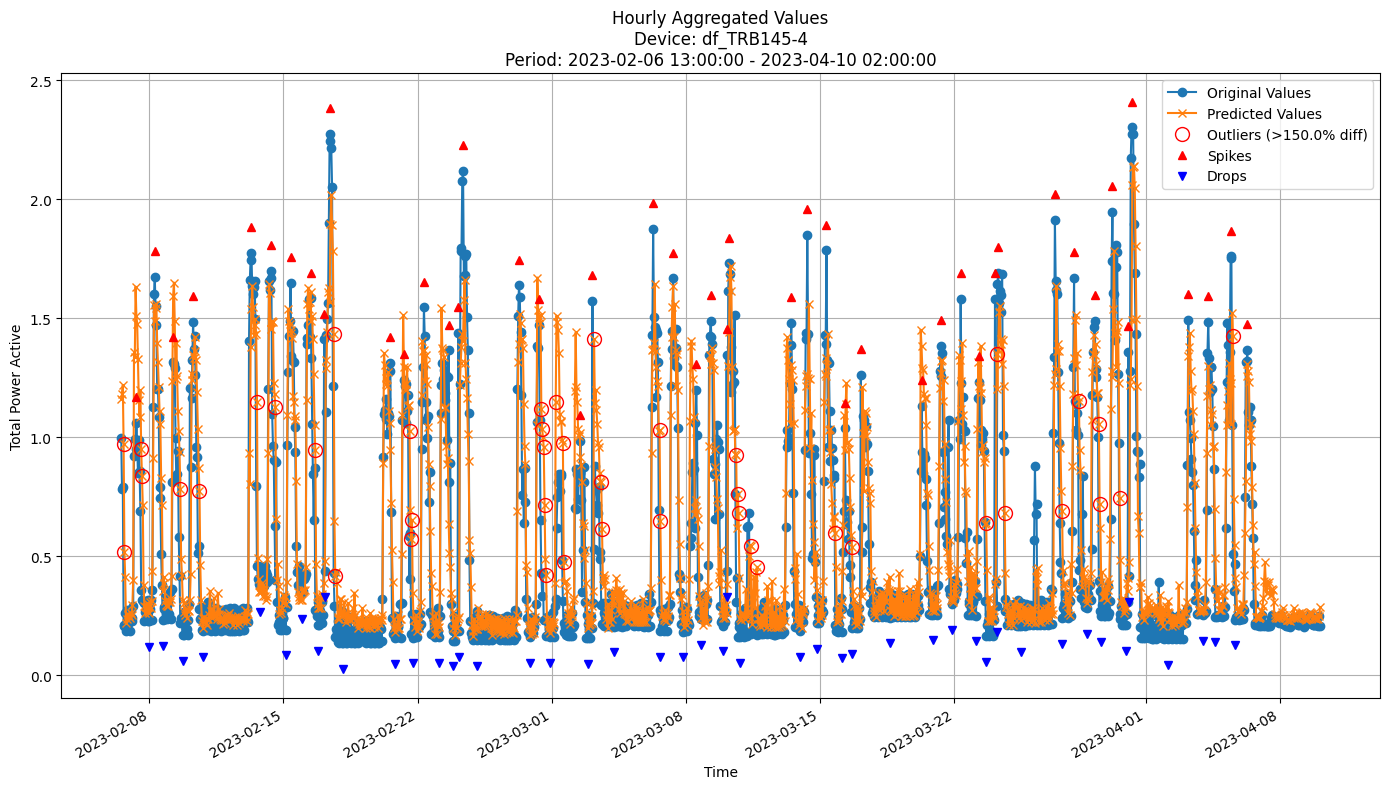


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2347
MAE: 0.1483
MAPE: 34.6715%

Directional Metrics:
Directional Accuracy: 59.0273%
First-Diff Correlation: 0.4102

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0750
  Recall: 0.0638
  F1 Score: 0.0690
Drops:
  Precision: 0.1795
  Recall: 0.1522
  F1 Score: 0.1647

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2750
  Recall: 0.2340
  F1 Score: 0.2529
Drops:
  Precision: 0.2308
  Recall: 0.1957
  F1 Score: 0.2118


In [22]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

grace_period = 10
delta = 0.5
max_depth = 10
tau = 0.05
leaf_prediction = "mean"

hoef = HoeffdingTreeRegressor(
        max_depth=max_depth,
        grace_period=grace_period,
        delta=delta,
        tau=tau,
        leaf_prediction=leaf_prediction
    )

# Results from hyperparam. tuning
# BEST RMSE: 0.258
#    Best Parameters: {'max_depth': 10, 'grace_period': 48, 'tau': 0.1, 'delta': 0.1}
# BEST MAE: 0.162
#    Best Parameters: {'max_depth': 15, 'grace_period': 48, 'tau': 0.1, 'delta': 0.1}
# BEST MAPE: 30.209%
#    Best Parameters: {'max_depth': 15, 'grace_period': 48, 'tau': 0.1, 'delta': 0.1}
# BEST DIR_ACCURACY: 54.170%
#    Best Parameters: {'max_depth': 5, 'grace_period': 0, 'tau': 0.1, 'delta': 0.005}
# BEST FIRST_DIFF_CORR: 41.677%
#    Best Parameters: {'max_depth': 3, 'grace_period': 0, 'tau': 0.1, 'delta': 0.05}
# BEST SPIKES_F1: 18.787%
#    Best Parameters: {'max_depth': 3, 'grace_period': 24, 'tau': 0.001, 'delta': 0.05}
# BEST DROPS_F1: 10.620%
#    Best Parameters: {'max_depth': 10, 'grace_period': 24, 'tau': 0.1, 'delta': 0.005}


In [24]:
hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=hoef, 
    train=train, 
    valid=valid, 
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3746
	MAE: 0.2556
	MAPE: 29.1036%

Directional Metrics:
	Directional Accuracy: 45.3055%
	First-Diff Correlation: 0.2171

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.1078
	MAE: 4.0

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3566
	MAE: 0.2247
	MAPE: 33.0720%

Directional Metrics:
	Directional Accuracy: 52.0119%
	First-Diff Correlation: 0.2745

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.8259
	MAE: 3.0

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2995
	MAE: 0.1876
	MAPE: 36.9397%

Directional Metrics:
	Directional Accuracy: 49.4784%
	First-Diff Correlation: 0.2496

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1053
		Recall: 0.1053
		F1: 0.1053
	Drops:
		Precision: 0.0500
		Recall: 0.0500
		F1: 0.0500

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3158
		Recall: 0.3158
		F1: 0.3158
	Drops:
		Precision: 0.2500
		Recall: 0.2500
		F1: 0.2500
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 2.7277
	MAE: 2.2

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1994
	MAE: 0.1174
	MAPE: 28.7214%

Directional Metrics:
	Directional Accuracy: 57.3248%
	First-Diff Correlation: 0.2887

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2500
		Recall: 0.2500
		F1: 0.2500
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2500
		Recall: 0.2500
		F1: 0.2500
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.7537
	MAE: 1.5

#### Results

In [25]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2769 ± 0.0336
	MAE: 0.1652 ± 0.0247
	MAPE: 28.4640% ± 5.7028%

	Directional Metrics:
		Directional Accuracy: 36.6377% ± 6.1702%
		First-Diff Correlation: 0.3328 ± 0.0960

	Immediate Detection (delta=0):
		Spike Precision: 0.0602 ± 0.0696
		Spike Recall: 0.0578 ± 0.0692
		Spike F1: 0.0581 ± 0.0676
		Drop Precision: 0.0362 ± 0.0435
		Drop Recall: 0.0398 ± 0.0463
		Drop F1: 0.0373 ± 0.0436

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1540 ± 0.1789
		Spike Recall: 0.1474 ± 0.1759
		Spike F1: 0.1486 ± 0.1728
		Drop Precision: 0.0512 ± 0.0666
		Drop Recall: 0.0537 ± 0.0640
		Drop F1: 0.0516 ± 0.0639
Daily Metrics:
	RMSE: 2.6302 ± 0.6186
	MAE: 2.0575 ± 0.5088
	MAPE: 14.6692% ± 4.4945%

	Directional Metrics:
		Directional Accuracy: 76.5479% ± 4.1340%
		First-Diff Correlation: 0.9250 ± 0.0506

	Immediate Detection (delta=0):

#### Training plots
Plot only the last period of predictions

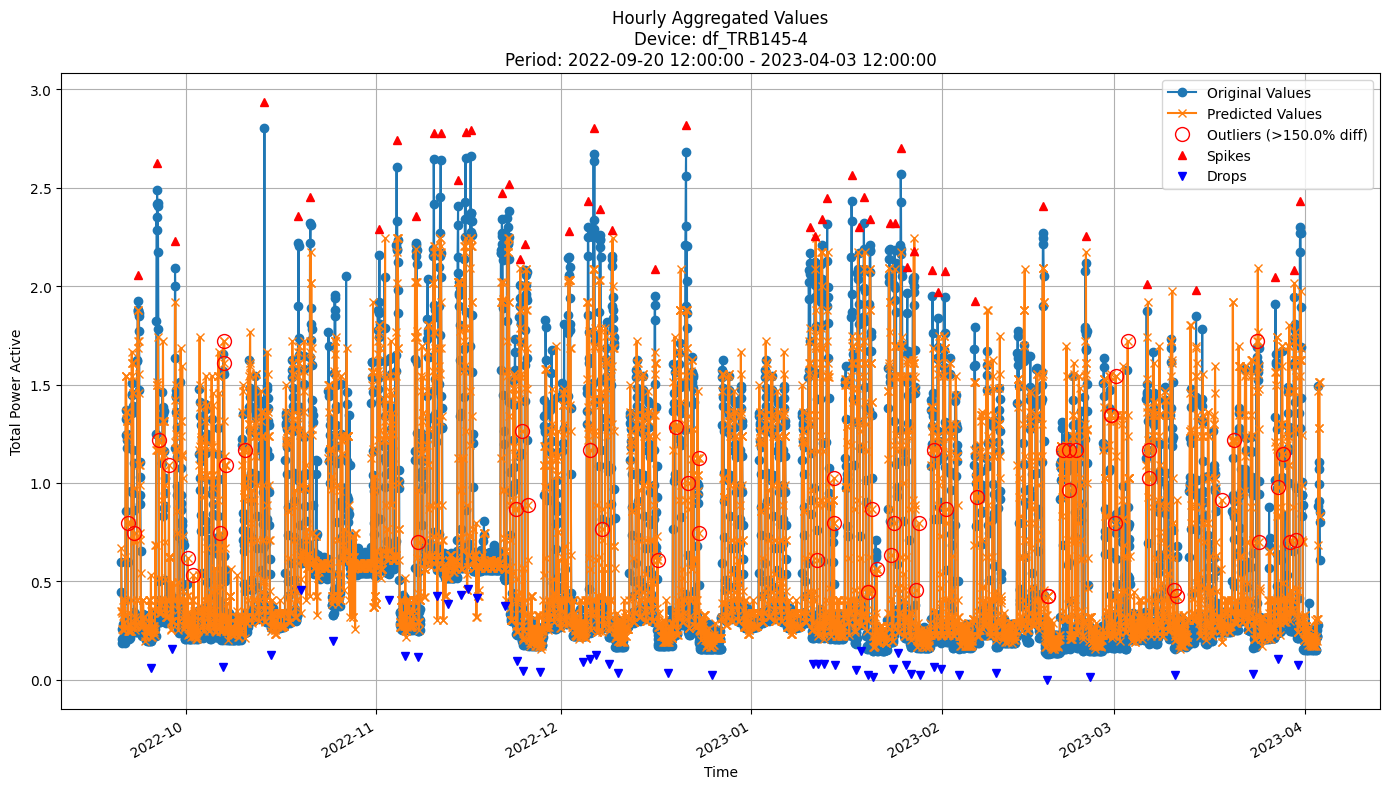


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2446
MAE: 0.1418
MAPE: 25.3569%

Directional Metrics:
Directional Accuracy: 43.6538%
First-Diff Correlation: 0.4135

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1500
  Recall: 0.1224
  F1 Score: 0.1348
Drops:
  Precision: 0.0909
  Recall: 0.1042
  F1 Score: 0.0971

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4000
  Recall: 0.3265
  F1 Score: 0.3596
Drops:
  Precision: 0.1273
  Recall: 0.1458
  F1 Score: 0.1359


In [26]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

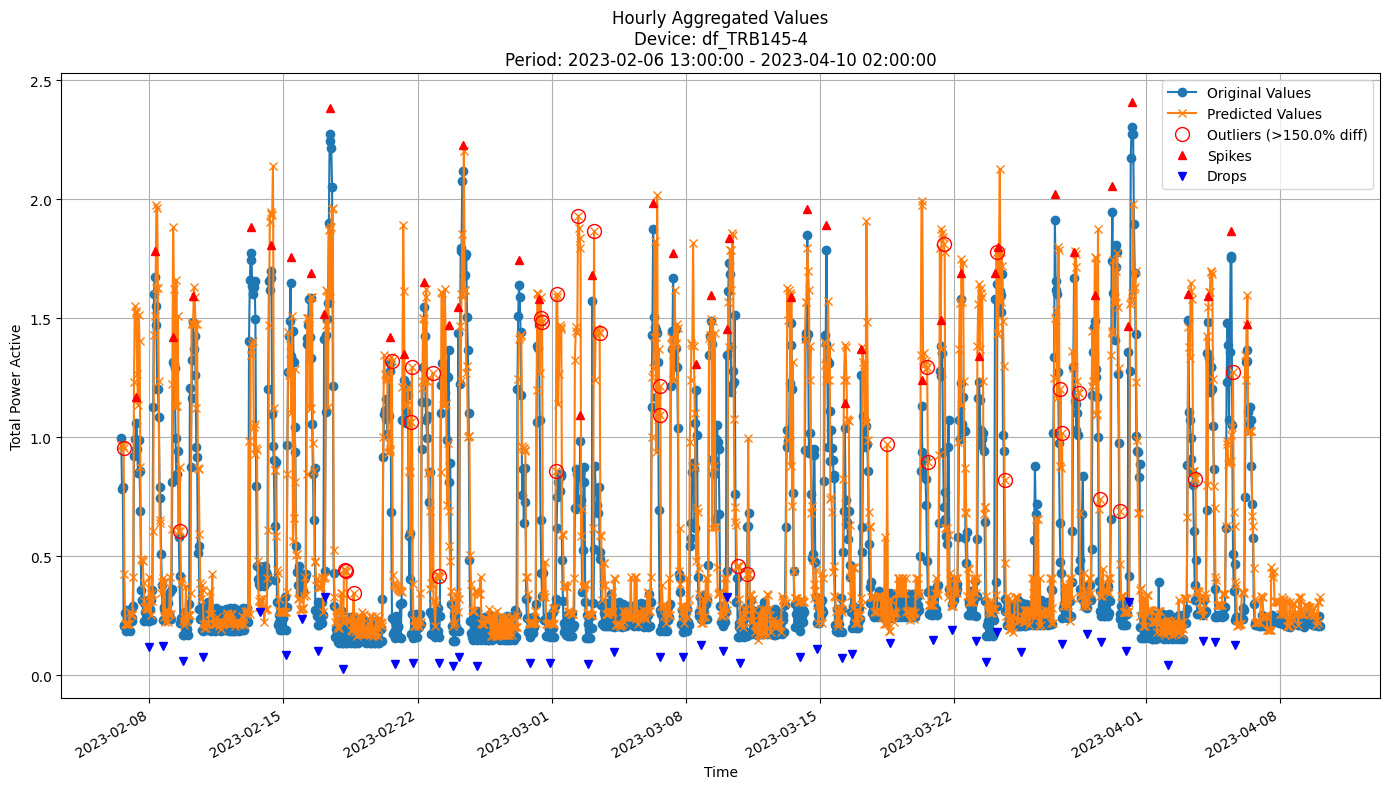


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2891
MAE: 0.1766
MAPE: 37.6427%

Directional Metrics:
Directional Accuracy: 52.2318%
First-Diff Correlation: 0.2959

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1707
  Recall: 0.1489
  F1 Score: 0.1591
Drops:
  Precision: 0.0500
  Recall: 0.0435
  F1 Score: 0.0465

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3415
  Recall: 0.2979
  F1 Score: 0.3182
Drops:
  Precision: 0.2500
  Recall: 0.2174
  F1 Score: 0.2326


In [27]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [28]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 10
max_features = 0.8
grace_period = 10
split_confidence = 0.5
depth = 10
tau = 0.01

arf_hf = ARFRegressor(
        n_models=n_models,
        max_features=max_features,
        aggregation_method='median',
        grace_period=grace_period,
        max_depth=depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
    )

In [29]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=arf_hf,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3631
	MAE: 0.2355
	MAPE: 27.3743%

Directional Metrics:
	Directional Accuracy: 52.1610%
	First-Diff Correlation: 0.3317

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.4454
	MAE: 4.2

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3245
	MAE: 0.2214
	MAPE: 39.9123%

Directional Metrics:
	Directional Accuracy: 57.9732%
	First-Diff Correlation: 0.4104

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.9443
	MAE: 3.1

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2498
	MAE: 0.1676
	MAPE: 37.3576%

Directional Metrics:
	Directional Accuracy: 51.8629%
	First-Diff Correlation: 0.3531

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1053
		Recall: 0.1000
		F1: 0.1026

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3158
		Recall: 0.3158
		F1: 0.3158
	Drops:
		Precision: 0.1579
		Recall: 0.1500
		F1: 0.1538
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 2.3846
	MAE: 1.9

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1904
	MAE: 0.1279
	MAPE: 40.8609%

Directional Metrics:
	Directional Accuracy: 59.2357%
	First-Diff Correlation: 0.4171

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3333
		Recall: 0.2500
		F1: 0.2857
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 2.2832
	MAE: 1.8

#### Results

In [30]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2586 ± 0.0565
	MAE: 0.1637 ± 0.0445
	MAPE: 31.6056% ± 11.1158%

	Directional Metrics:
		Directional Accuracy: 58.5306% ± 7.2030%
		First-Diff Correlation: 0.4946 ± 0.1244

	Immediate Detection (delta=0):
		Spike Precision: 0.1061 ± 0.1370
		Spike Recall: 0.0573 ± 0.0757
		Spike F1: 0.0737 ± 0.0958
		Drop Precision: 0.0501 ± 0.0579
		Drop Recall: 0.0278 ± 0.0332
		Drop F1: 0.0353 ± 0.0413

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1996 ± 0.2542
		Spike Recall: 0.1079 ± 0.1412
		Spike F1: 0.1387 ± 0.1784
		Drop Precision: 0.0631 ± 0.0757
		Drop Recall: 0.0347 ± 0.0422
		Drop F1: 0.0443 ± 0.0529
Daily Metrics:
	RMSE: 3.1903 ± 0.9528
	MAE: 2.4899 ± 0.8054
	MAPE: 20.5581% ± 9.5556%

	Directional Metrics:
		Directional Accuracy: 76.8486% ± 5.8319%
		First-Diff Correlation: 0.8792 ± 0.1838

	Immediate Detection (delta=0)

#### Training plots

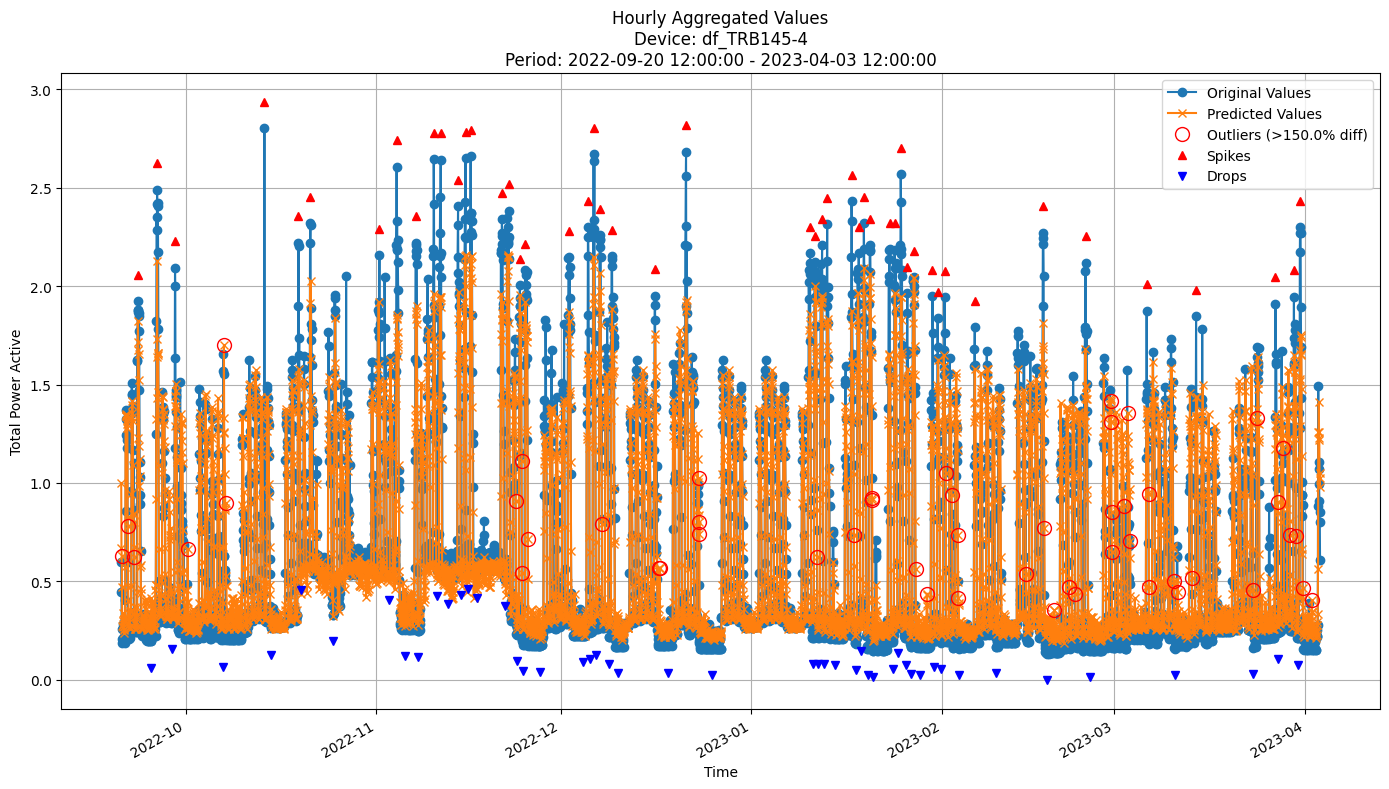


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2175
MAE: 0.1308
MAPE: 25.1906%

Directional Metrics:
Directional Accuracy: 62.5641%
First-Diff Correlation: 0.5781

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2647
  Recall: 0.1837
  F1 Score: 0.2169
Drops:
  Precision: 0.1143
  Recall: 0.0833
  F1 Score: 0.0964

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.3469
  F1 Score: 0.4096
Drops:
  Precision: 0.1429
  Recall: 0.1042
  F1 Score: 0.1205


In [31]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

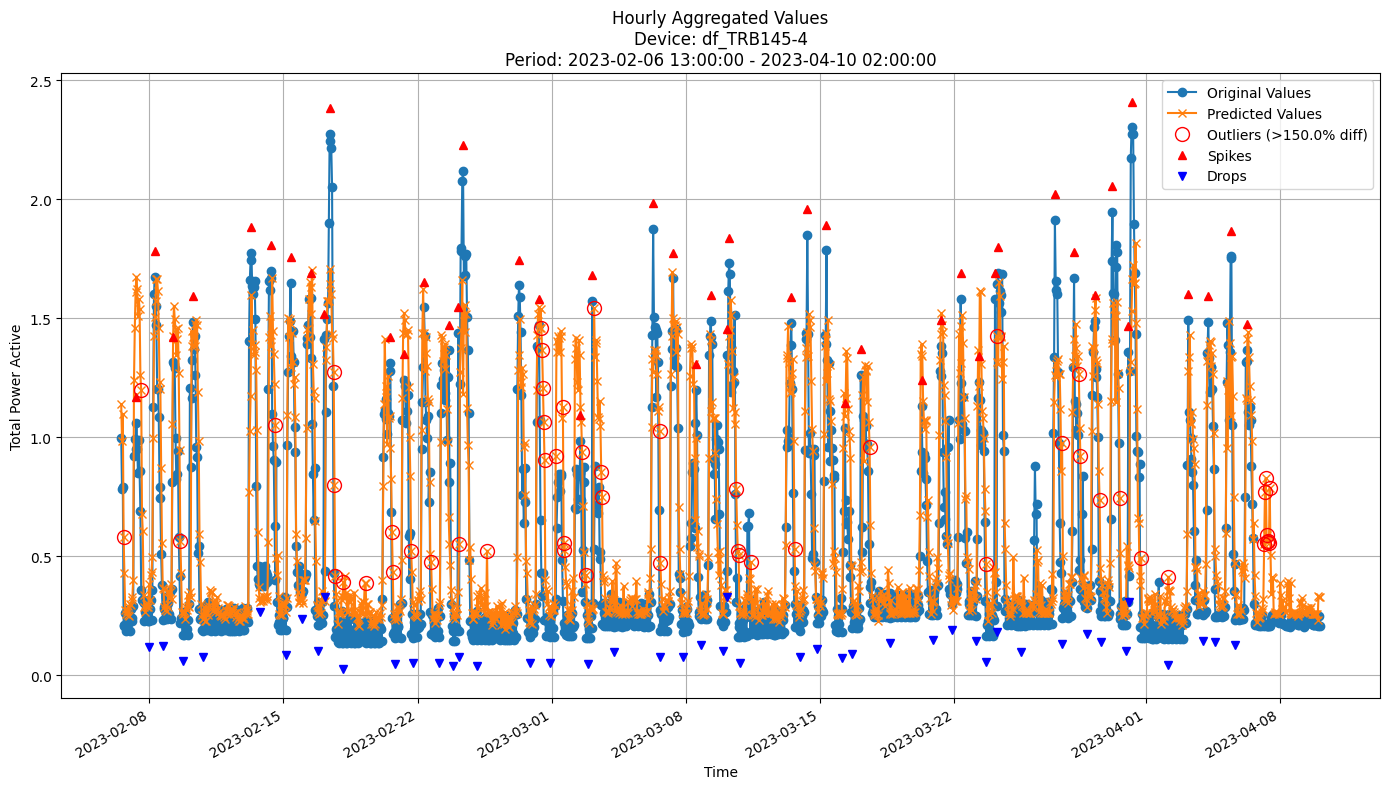


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2560
MAE: 0.1695
MAPE: 41.2028%

Directional Metrics:
Directional Accuracy: 58.0280%
First-Diff Correlation: 0.4114

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1163
  Recall: 0.1064
  F1 Score: 0.1111
Drops:
  Precision: 0.0930
  Recall: 0.0870
  F1 Score: 0.0899

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4186
  Recall: 0.3830
  F1 Score: 0.4000
Drops:
  Precision: 0.1395
  Recall: 0.1304
  F1 Score: 0.1348


In [32]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario
grace_period = 10
split_confidence = 0.005
depth = 50
eagerness = 1000
grace_period_depth = 0 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes
option = 'hf'

fodt = fastodt.FastODT(
        depth=depth,
        grace_period=grace_period,
        split_confidence=split_confidence,
        option=option,
        eagerness = eagerness,
        grace_period_depth = grace_period_depth
    )

# Results from hyperparam. tuning
# BEST RMSE: 0.332
#    Best Parameters: {'depth': 50, 'grace_period': 10, 'grace_period_depth': -1, 'eagerness': 0, 'split_confidence': 0.1, 'option': 'hf'}
# BEST MAE: 0.247
#    Best Parameters: {'depth': 70, 'grace_period': 10, 'grace_period_depth': 0, 'eagerness': 200, 'split_confidence': 0.05, 'option': 'hf'}
# BEST MAPE: 42.162%
#    Best Parameters: {'depth': 5, 'grace_period': 0, 'grace_period_depth': -1, 'eagerness': 100, 'split_confidence': 0.005, 'option': 'hf'}
# BEST DIR_ACCURACY: 60.316%
#    Best Parameters: {'depth': 50, 'grace_period': 10, 'grace_period_depth': 0, 'eagerness': 1000, 'split_confidence': 0.005, 'option': 'hf'}
# BEST FIRST_DIFF_CORR: 49.973%
#    Best Parameters: {'depth': 50, 'grace_period': 10, 'grace_period_depth': 0, 'eagerness': 1000, 'split_confidence': 0.005, 'option': 'hf'}
# BEST SPIKES_F1: 23.121%
#    Best Parameters: {'depth': 50, 'grace_period': 24, 'grace_period_depth': 1, 'eagerness': 0, 'split_confidence': 0.001, 'option': 'hf'}
# BEST DROPS_F1: 9.139%
#    Best Parameters: {'depth': 30, 'grace_period': 35, 'grace_period_depth': 1, 'eagerness': 0, 'split_confidence': 0.001, 'option': 'hf'}

In [34]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=fodt, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5257
	MAE: 0.3765
	MAPE: 42.1549%

Directional Metrics:
	Directional Accuracy: 49.1803%
	First-Diff Correlation: 0.1374

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 8.8017
	MAE: 7.2

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5832
	MAE: 0.4373
	MAPE: 78.8244%

Directional Metrics:
	Directional Accuracy: 53.2042%
	First-Diff Correlation: 0.2809

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 9.1187
	MAE: 7.7

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3356
	MAE: 0.2709
	MAPE: 82.1466%

Directional Metrics:
	Directional Accuracy: 56.1848%
	First-Diff Correlation: 0.3914

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.1107
	MAE: 4.0

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3622
	MAE: 0.2897
	MAPE: 115.6014%

Directional Metrics:
	Directional Accuracy: 51.5924%
	First-Diff Correlation: 0.5267

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 6.1564
	MAE: 4.

#### Results

In [35]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4377 ± 0.0237
	MAE: 0.3231 ± 0.0181
	MAPE: 69.8244% ± 5.3867%

	Directional Metrics:
		Directional Accuracy: 52.9933% ± 9.7540%
		First-Diff Correlation: 0.3661 ± 0.1152

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Daily Metrics:
	RMSE: 6.8994 ± 0.5951
	MAE: 5.6037 ± 0.4699
	MAPE: 52.3797% ± 2.3291%

	Directional Metrics:
		Directional Accuracy: 39.1296% ± 23.6474%
		First-Diff Correlation: 0.4362 ± 0.2474

	Immediate Detection (delta=0)

#### Training plots


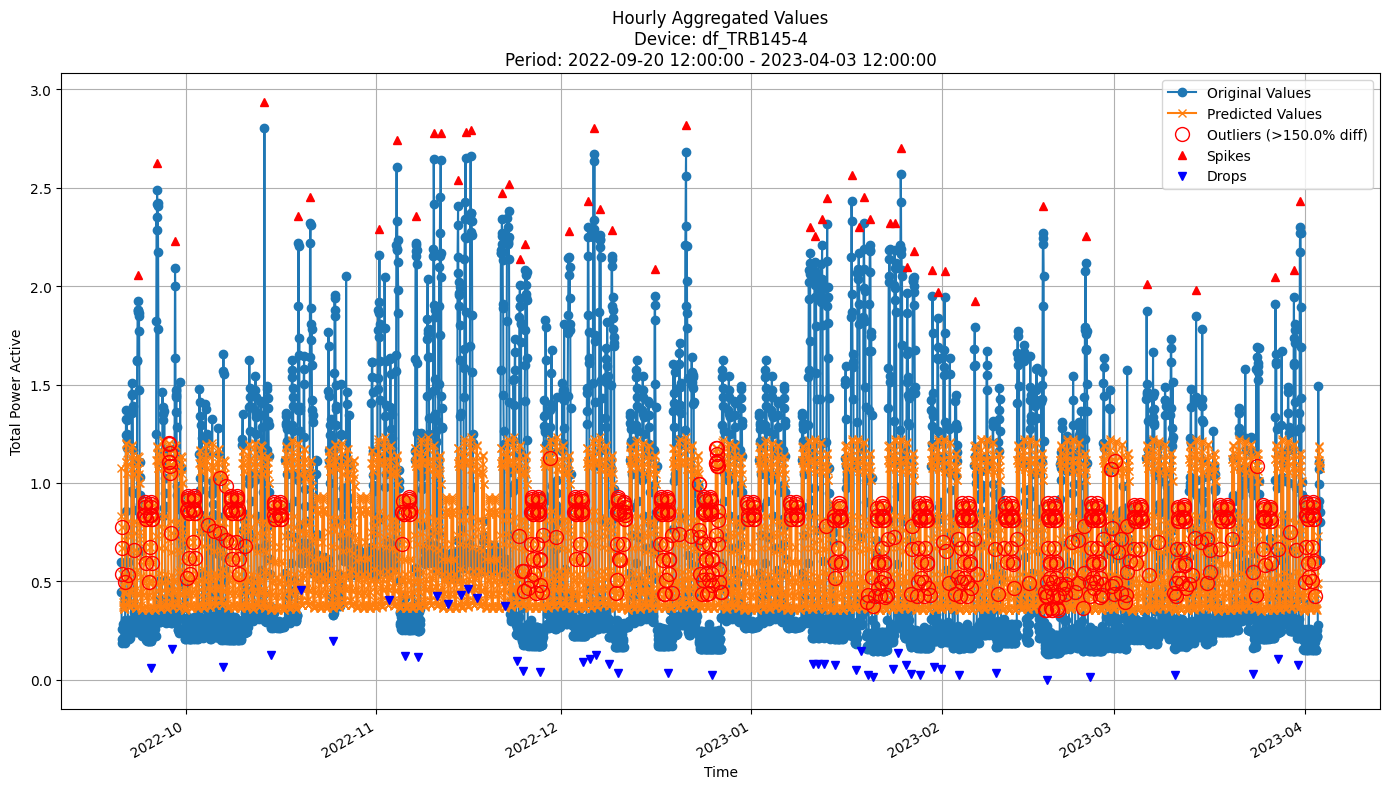


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4080
MAE: 0.3076
MAPE: 76.2470%

Directional Metrics:
Directional Accuracy: 58.4188%
First-Diff Correlation: 0.4767

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [36]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

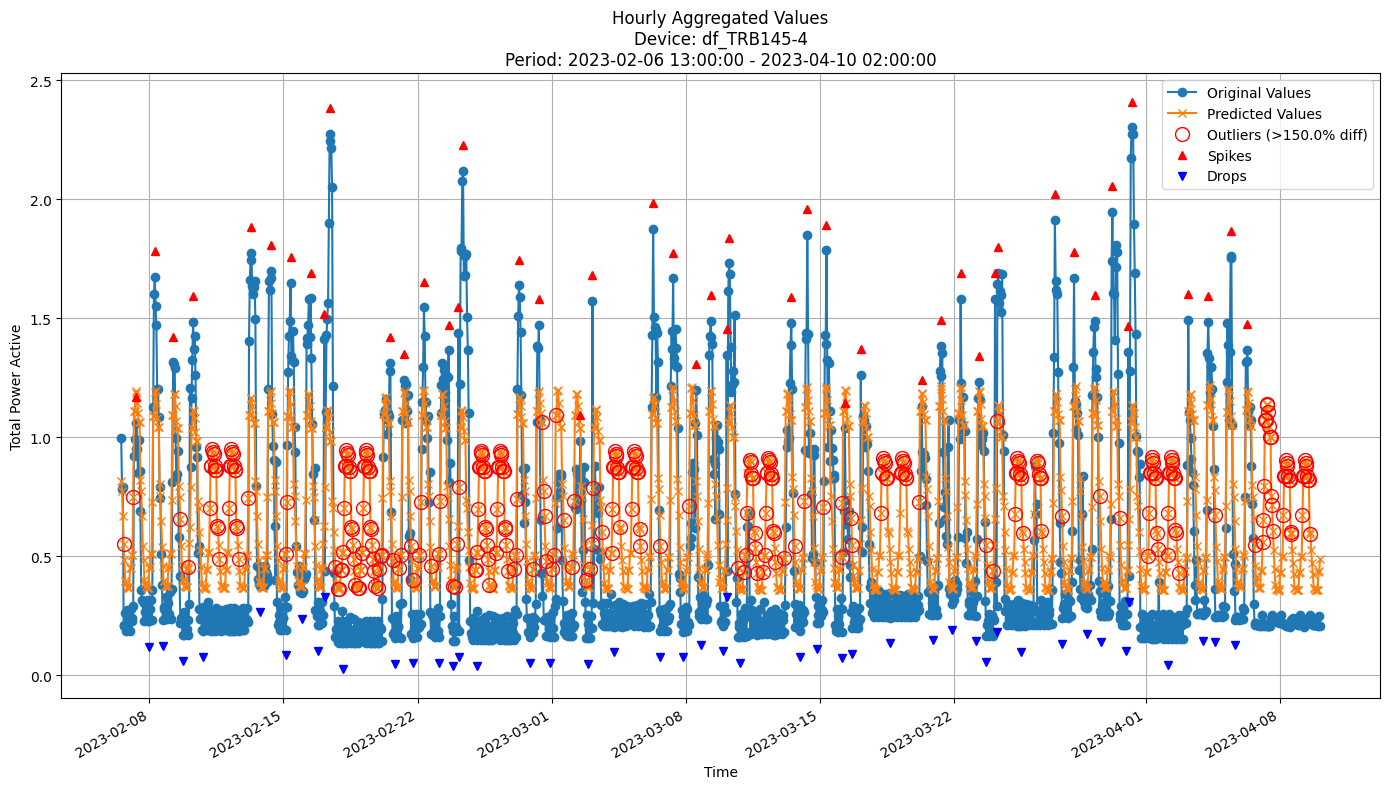


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3539
MAE: 0.2860
MAPE: 96.9629%

Directional Metrics:
Directional Accuracy: 54.7635%
First-Diff Correlation: 0.4228

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [37]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [38]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 20
grace_period = 0  # by default works for all leaves
aggregation_method = "mean"
split_confidence = 0.005
tau = 0.01
max_depth = 100
eagerness = 200

arf = ARFRegressorFODT(
        n_models=n_models,
        aggregation_method=aggregation_method,
        grace_period=grace_period,
        max_depth=max_depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
        max_feature=0.7,
        eagerness=eagerness,
    )


In [39]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=arf,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5125
	MAE: 0.3410
	MAPE: 38.0507%

Directional Metrics:
	Directional Accuracy: 57.0790%
	First-Diff Correlation: 0.2786

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2500
		Recall: 0.0909
		F1: 0.1333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 7.7897
	MAE: 6.5

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5535
	MAE: 0.4331
	MAPE: 86.5106%

Directional Metrics:
	Directional Accuracy: 57.5261%
	First-Diff Correlation: 0.4311

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 7.5318
	MAE: 6.2

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3075
	MAE: 0.2400
	MAPE: 65.7064%

Directional Metrics:
	Directional Accuracy: 56.7809%
	First-Diff Correlation: 0.4140

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.8159
	MAE: 3.0

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2651
	MAE: 0.2246
	MAPE: 74.6959%

Directional Metrics:
	Directional Accuracy: 54.1401%
	First-Diff Correlation: 0.6092

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.6881
	MAE: 2.9

#### Results

In [40]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4091 ± 0.0335
	MAE: 0.3067 ± 0.0372
	MAPE: 67.4887% ± 11.7236%

	Directional Metrics:
		Directional Accuracy: 61.3274% ± 1.6576%
		First-Diff Correlation: 0.4435 ± 0.0750

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Daily Metrics:
	RMSE: 6.1730 ± 0.6589
	MAE: 5.0588 ± 0.5920
	MAPE: 46.7213% ± 5.9630%

	Directional Metrics:
		Directional Accuracy: 67.7229% ± 5.1337%
		First-Diff Correlation: 0.7700 ± 0.0943

	Immediate Detection (delta=0)

#### Training plots


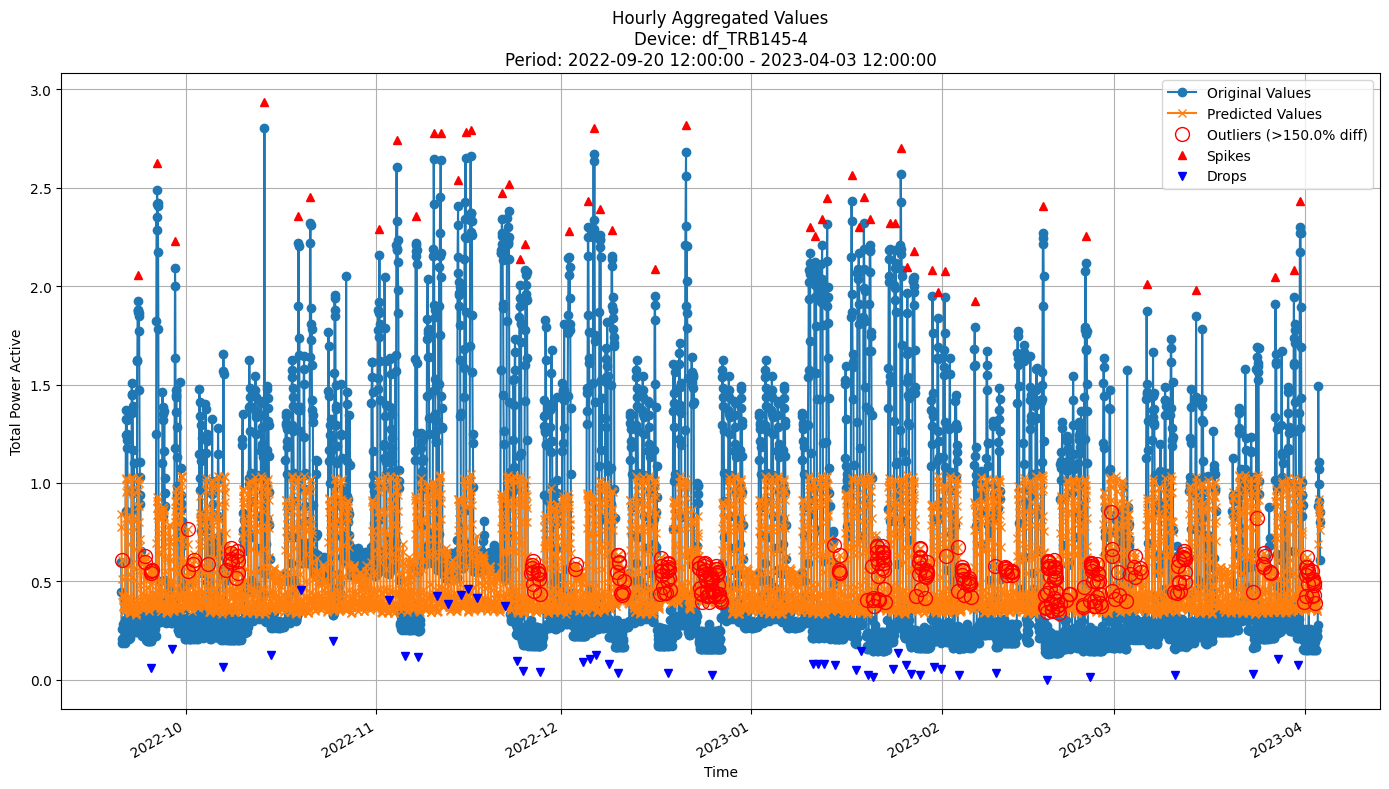


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4252
MAE: 0.2965
MAPE: 57.2403%

Directional Metrics:
Directional Accuracy: 60.5769%
First-Diff Correlation: 0.5146

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [41]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

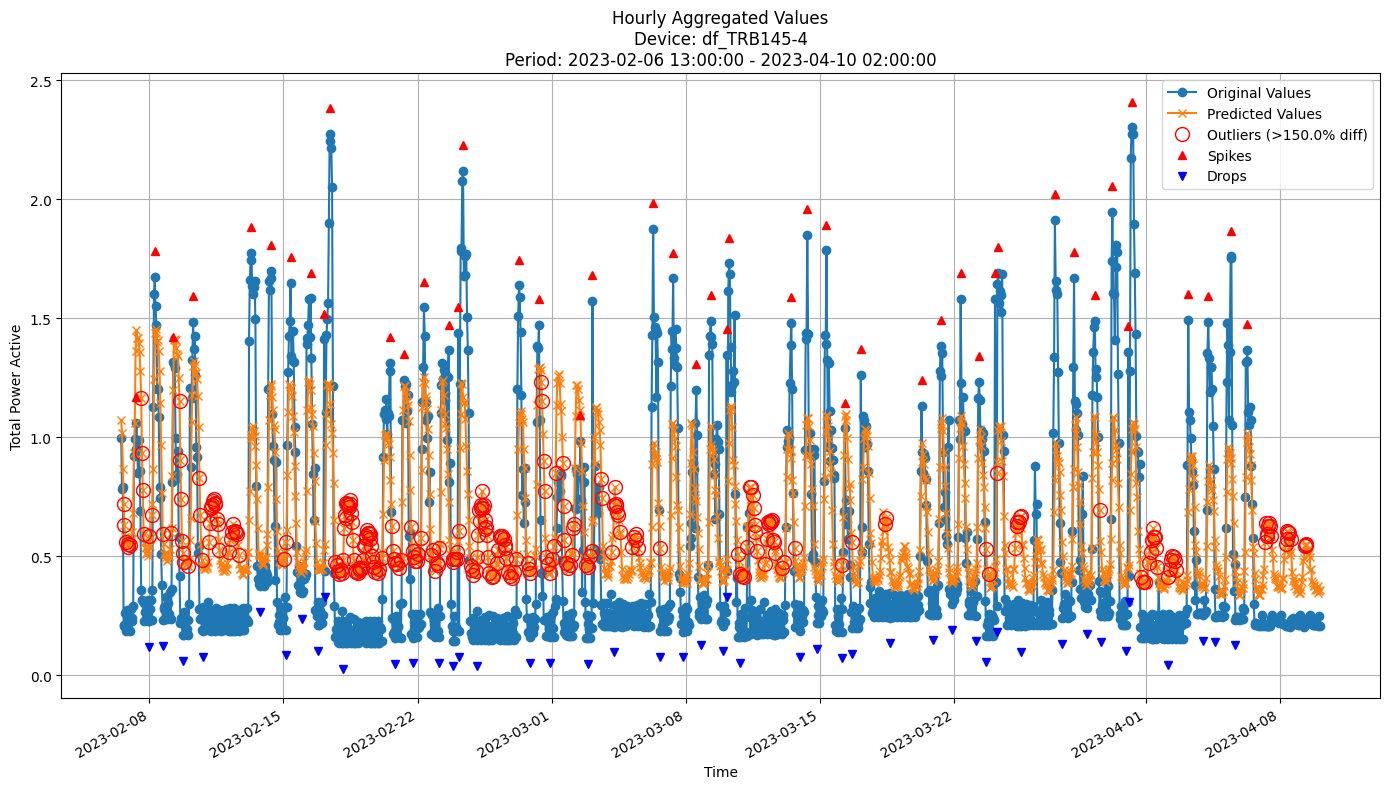


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3254
MAE: 0.2694
MAPE: 85.0513%

Directional Metrics:
Directional Accuracy: 57.0953%
First-Diff Correlation: 0.4546

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [42]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:
split_confidence_hf = 0.01
n_trees = 100
grace_period = 0
depth = 50
eagerness = 1000
learning_rate = 0.5
max_features = 1.0
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes
incb = IncubationBoost(
    fastodt.FastODT,
    length=n_trees,
    learning_rate=learning_rate,
    incubationMode = "DEFAULT",
    baseLearnerOptions = (depth, grace_period, split_confidence_hf, "hf", max_features, eagerness, grace_period_depth),
    verbose=False
    )

# Results from hyperparam. tuning (might need to UPDATE after new drift detection method)
# BEST RMSE: 0.357
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 70, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST MAE: 0.276
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 70, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST MAPE: 61.889%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (70, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST DIR_ACCURACY: 60.316%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (50, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST FIRST_DIFF_CORR: 49.973%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (50, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST SPIKES_F1: 6.190%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST DROPS_F1: 0.000%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}

In [44]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=incb, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6874
	MAE: 0.5356
	MAPE: 57.5567%

Directional Metrics:
	Directional Accuracy: 53.8003%
	First-Diff Correlation: 0.2830

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 13.7134
	MAE: 12

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6907
	MAE: 0.4565
	MAPE: 44.4226%

Directional Metrics:
	Directional Accuracy: 56.9300%
	First-Diff Correlation: 0.4240

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 12.4615
	MAE: 10

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3767
	MAE: 0.2384
	MAPE: 36.3864%

Directional Metrics:
	Directional Accuracy: 58.1222%
	First-Diff Correlation: 0.4657

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.0526
		F1: 0.1000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 6.2922
	MAE: 5.2

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2975
	MAE: 0.1924
	MAPE: 44.2997%

Directional Metrics:
	Directional Accuracy: 56.6879%
	First-Diff Correlation: 0.4639

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.5000
		F1: 0.6667
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.3136
	MAE: 3.2

#### Results

In [45]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.5283 ± 0.0372
	MAE: 0.3550 ± 0.0353
	MAPE: 43.0863% ± 1.4550%

	Directional Metrics:
		Directional Accuracy: 63.0876% ± 9.0861%
		First-Diff Correlation: 0.6015 ± 0.1105

	Immediate Detection (delta=0):
		Spike Precision: 0.1429 ± 0.3499
		Spike Recall: 0.0029 ± 0.0071
		Spike F1: 0.0057 ± 0.0140
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1429 ± 0.3499
		Spike Recall: 0.0029 ± 0.0071
		Spike F1: 0.0057 ± 0.0140
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Daily Metrics:
	RMSE: 9.9376 ± 0.9933
	MAE: 8.1191 ± 0.9844
	MAPE: 42.9314% ± 2.6442%

	Directional Metrics:
		Directional Accuracy: 78.2284% ± 2.2076%
		First-Diff Correlation: 0.8383 ± 0.1044

	Immediate Detection (delta=0):

#### Train plots

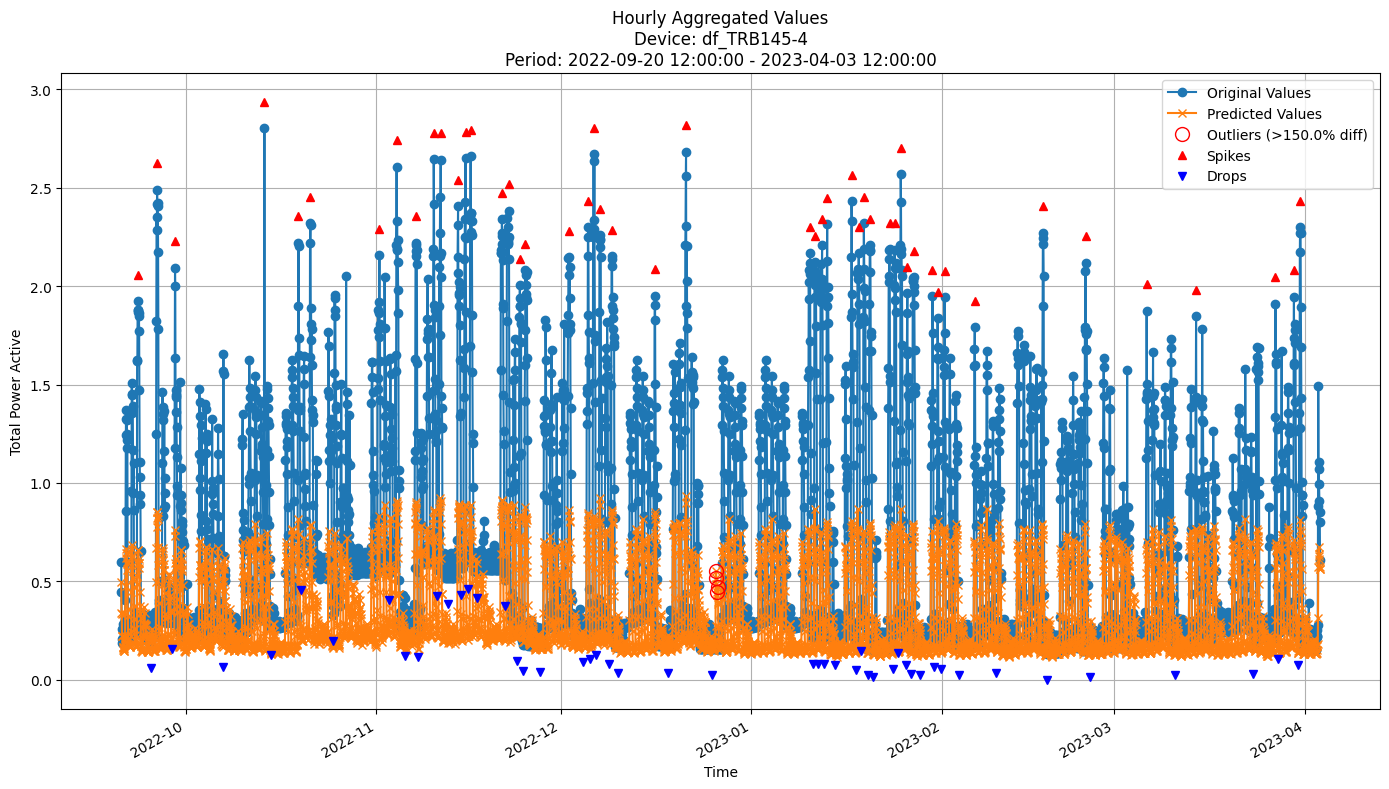


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4984
MAE: 0.3289
MAPE: 40.9555%

Directional Metrics:
Directional Accuracy: 71.0043%
First-Diff Correlation: 0.7067

Immediate Detection (delta=0):
Spikes:
  Precision: 1.0000
  Recall: 0.0204
  F1 Score: 0.0400
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.0204
  F1 Score: 0.0400
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [46]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

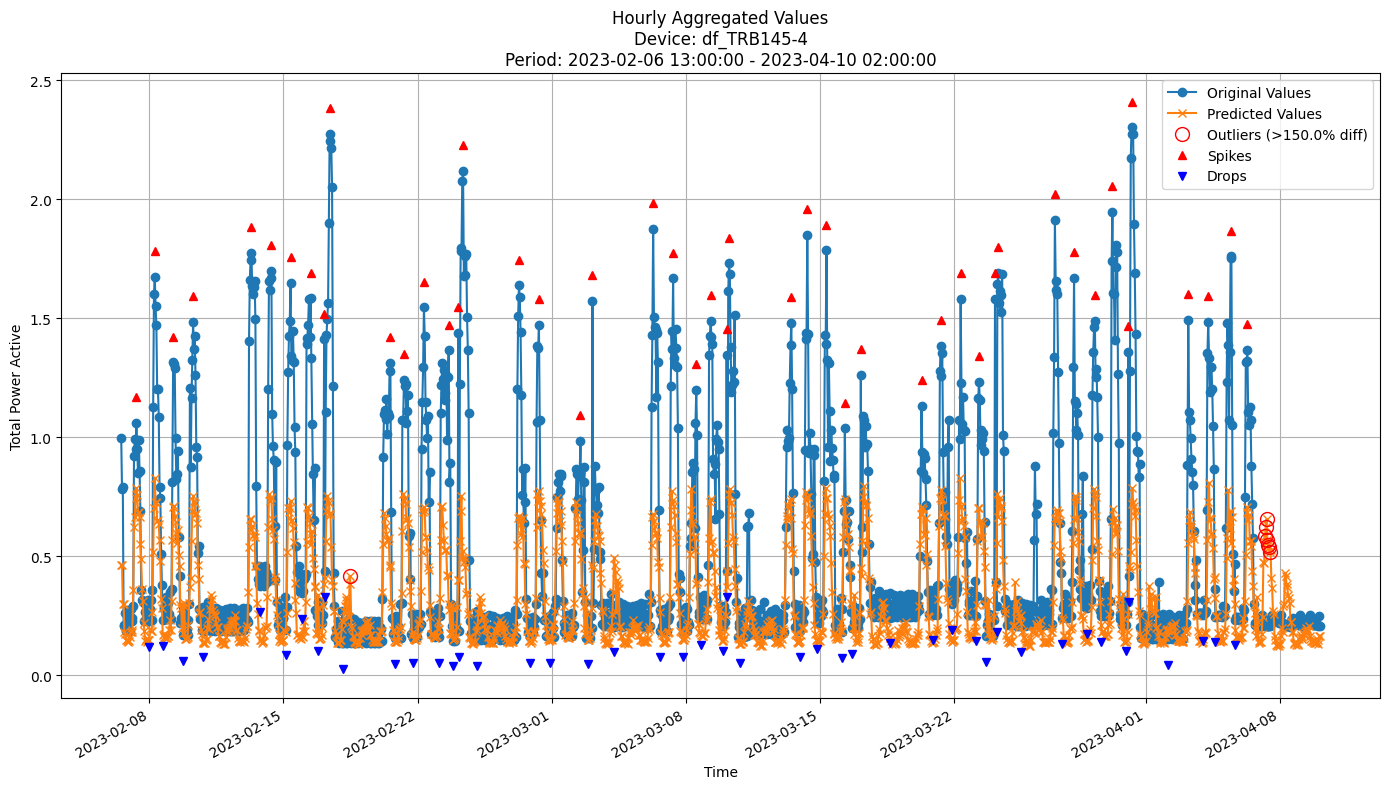


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3767
MAE: 0.2318
MAPE: 36.5213%

Directional Metrics:
Directional Accuracy: 57.8281%
First-Diff Correlation: 0.4860

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.0213
  F1 Score: 0.0417
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [47]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [48]:
last_valid_dates = valid[-1][0][valid[-1][0][:, 1] == "df_TRB145-4"][:, 0]
test_dates = test[0][test[0][:, 1] == "df_TRB145-4"][:, 0]
print(f"Last validation set range: {last_valid_dates[0]} - {last_valid_dates[-1]}")
print(f"Test range: {test_dates[0]} - {test_dates[-1]}")
print(f"Test set length: {len(test_dates)}")

Last validation set range: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
Test range: 2023-04-10 04:00:00 - 2023-05-30 18:00:00
Test set length: 1215


In [49]:
# Initialize the models beforehand to run this cell
models = [baseline, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
model_test_results = {}
for model in models:
    if model in [gbdt, rf]:
        # Batch learning models
        incremental = False
        update_freq = "14D"
        print(f"Model: {model.__class__.__name__} - update_freq: {update_freq}")
    else:
        # Incremental learning models
        incremental = True
        update_freq = "1h"
        print(f"Model: {model.__class__.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model=model, 
        train=train, 
        valid=valid,
        test=test,
        incremental=incremental, 
        data_freq=DATA_FREQUENCY,
        update_freq=update_freq,
        spike_prominence=1.,
        normalize_robust=False,
        predict_train=False,
        verbose=True
    )
    model_test_results[model.__class__.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-10 02:00:00
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 04:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2078
	MAE: 0.0964
	MAPE: 16.4499%

Directional Metrics:
	Directional Accuracy: 48.8468%
	First-Diff Correlation: 0.1843

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0312
	MAE: 0.0225
	MAPE: 0.1695%

Direction

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Metrics for Device: df_TRB145-4 | Period: 2023-04-10 04:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2104
	MAE: 0.1248
	MAPE: 26.2313%

Directional Metrics:
	Directional Accuracy: 54.6129%
	First-Diff Correlation: 0.4386

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1714
		Recall: 0.1364
		F1: 0.1519
	Drops:
		Precision: 0.0588
		Recall: 0.0465
		F1: 0.0519

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5429
		Recall: 0.4318
		F1: 0.4810
	Drops:
		Precision: 0.1176
		Recall: 0.0930
		F1: 0.1039
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.9786
	MAE: 1.5960
	MAPE: 14.0079%

Directional Metrics:
	Directional Accuracy: 74.0000%
	First-Diff Correlation: 0.9389

Immediate Detection (delta=0)

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

... (7 outputs left out)

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-10 02:00:00
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 04:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3130
	MAE: 0.2201
	MAPE: 54.9144%

Directional Metrics:
	Directional Accuracy: 59.9671%
	First-Diff Correlation: 0.4770

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1316
		Recall: 0.1136
		F1: 0.1220
	Drops:
		Precision: 0.0541
		Recall: 0.0465
		F1: 0.0500

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5263
		Recall: 0.4545
		F1: 0.4878
	Drops:
		Precision: 0.2973
		Recall: 0.2558
		F1: 0.2750
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.1526
	MAE: 3.1706
	MAPE: 34.3146%

Directio

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-10 02:00:00
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 04:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3906
	MAE: 0.2355
	MAPE: 38.8950%

Directional Metrics:
	Directional Accuracy: 59.2257%
	First-Diff Correlation: 0.4587

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1463
		Recall: 0.1364
		F1: 0.1412
	Drops:
		Precision: 0.0750
		Recall: 0.0698
		F1: 0.0723

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5610
		Recall: 0.5227
		F1: 0.5412
	Drops:
		Precision: 0.2750
		Recall: 0.2558
		F1: 0.2651
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 6.6292
	MAE: 5.2061
	MAPE: 37.7476%

Directio

In [50]:
for model in models:
    model_test_results[model.__class__.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__class__.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [51]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [52]:
MODEL_TEST_METRICS = {
    "Baseline": model_test_results[baseline.__class__.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__class__.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__class__.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__class__.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__class__.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__class__.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__class__.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__class__.__name__]["test_metrics"],
}

In [ ]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f}"# ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

for device_id in device_ids:
    rows = []
    for model, mdict in MODEL_TEST_METRICS.items():
        if device_id in mdict and AGG_LEVEL in mdict[device_id]:
            vals = mdict[device_id][AGG_LEVEL]
            row = [model]
            for m in METRICS:
                is_perc = (m in PERC_METRICS)
                row.append(format_metric(vals.get(m, None), is_perc=is_perc))
            rows.append(row)
    df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                     "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)",
                                     "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
    print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL}")
    display(df)


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.208,0.096,16.450,48.847,18.428,0.000,100.000,0.000,100.000
1,GBDT,0.210,0.125,26.231,54.613,43.860,15.190,48.101,5.195,10.390
2,RandomForest,0.223,0.129,26.880,57.166,40.782,10.127,45.570,2.597,15.584
3,HoeffdingTree,0.284,0.165,32.638,49.753,34.349,7.143,33.333,0.000,12.195
4,ARF_Hoeffding,0.265,0.159,31.960,55.437,34.451,2.500,40.000,5.128,23.077
5,FastODT,0.365,0.282,86.842,53.789,50.532,16.842,42.105,6.452,21.505
6,ARF_FastODT,0.313,0.220,54.914,59.967,47.701,12.195,48.780,5.000,27.500
7,IncubationBoost,0.391,0.236,38.895,59.226,45.872,14.118,54.118,7.229,26.506


## Validation results

In [ ]:
MODEL_VALID_METRICS = {
    "Baseline": baseline_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

for device_id in device_ids:
    rows = []
    for model, mdict in MODEL_VALID_METRICS.items():
        if device_id in mdict and AGG_LEVEL in mdict[device_id]:
            vals = mdict[device_id][AGG_LEVEL]
            row = [model]
            for m in METRICS:
                is_perc = (m in PERC_METRICS)
                row.append(format_metric(vals.get(m, None), is_perc=is_perc))
            rows.append(row)
    df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                     "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
    print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL}")
    display(df)


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.228 ± 0.041,0.129 ± 0.030,23.957 ± 7.384,39.392 ± 4.644,18.383 ± 19.704,0.000 ± 0.000,85.714 ± 34.993,0.000 ± 0.000,83.287 ± 34.343
1,GBDT,0.249 ± 0.061,0.159 ± 0.052,33.496 ± 5.359,62.475 ± 7.104,38.209 ± 9.705,10.814 ± 11.126,35.111 ± 29.830,10.261 ± 9.802,13.652 ± 13.368
2,RandomForest,0.112 ± 0.011,0.066 ± 0.006,12.061 ± 1.329,78.026 ± 1.800,87.855 ± 3.247,20.657 ± 19.604,26.994 ± 27.588,5.345 ± 9.743,7.621 ± 13.705
3,HoeffdingTree,0.293 ± 0.057,0.185 ± 0.043,33.554 ± 4.498,52.217 ± 3.570,31.919 ± 7.951,12.040 ± 8.997,27.164 ± 20.215,2.566 ± 3.039,12.302 ± 10.896
4,ARF_Hoeffding,0.265 ± 0.061,0.175 ± 0.042,36.376 ± 6.671,58.814 ± 4.784,45.298 ± 9.825,8.673 ± 10.416,33.337 ± 24.486,7.708 ± 7.466,15.253 ± 18.465
5,FastODT,0.438 ± 0.091,0.338 ± 0.061,87.861 ± 22.489,54.911 ± 4.355,39.741 ± 13.265,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
6,ARF_FastODT,0.397 ± 0.099,0.320 ± 0.069,84.320 ± 25.183,58.895 ± 3.952,49.261 ± 12.026,0.000 ± 0.000,1.905 ± 4.666,0.000 ± 0.000,0.000 ± 0.000
7,IncubationBoost,0.504 ± 0.153,0.336 ± 0.120,43.088 ± 6.873,57.981 ± 2.497,46.809 ± 8.989,0.000 ± 0.000,10.952 ± 23.005,0.000 ± 0.000,0.000 ± 0.000


### By-period validation results

In [55]:
MODEL_VALID_PERIOD_METRICS = {
    "Baseline": baseline_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)


In [56]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,36.066,56.036,60.209,45.306,52.161,49.180,57.079,53.800,51.229625
Period 2,38.301,59.165,59.314,52.012,57.973,53.204,57.526,56.930,54.303125
Period 3,50.224,74.963,72.131,54.247,64.083,63.934,67.213,61.997,63.599000
Period 4,38.152,68.852,68.554,53.502,62.593,56.334,61.550,60.656,58.774125
Period 5,35.469,65.723,66.468,53.651,63.785,53.949,57.973,57.675,56.836625
Period 6,37.407,53.353,52.608,49.478,51.863,56.185,56.781,58.122,51.974625
Period 7,40.127,59.236,54.140,57.325,59.236,51.592,54.140,56.688,54.060500



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,2.235,3.129,-0.895,6.706,5.812,4.024,0.447,3.130,3.073
Period 3 - Period 2,11.923,15.798,12.817,2.235,6.110,10.730,9.687,5.067,9.296
Period 4 - Period 3,-12.072,-6.111,-3.577,-0.745,-1.490,-7.600,-5.663,-1.341,-4.825
Period 5 - Period 4,-2.683,-3.129,-2.086,0.149,1.192,-2.385,-3.577,-2.981,-1.938
Period 6 - Period 5,1.938,-12.370,-13.860,-4.173,-11.922,2.236,-1.192,0.447,-4.862
Period 7 - Period 6,2.720,5.883,1.532,7.847,7.373,-4.593,-2.641,-1.434,2.086


#### MAPE (lower is better)

In [57]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,17.404,31.690,21.388,29.104,27.374,42.155,38.051,57.557,33.090375
Period 2,23.446,40.876,32.348,33.072,39.912,78.824,86.511,44.423,47.426500
Period 3,19.005,24.037,22.384,28.871,25.597,87.423,101.884,43.248,44.056125
Period 4,31.500,39.670,37.042,37.726,38.402,101.478,116.561,40.873,55.406500
Period 5,32.715,33.149,35.717,40.443,45.128,107.397,106.831,34.827,54.525875
Period 6,31.064,35.139,35.559,36.940,37.358,82.147,65.706,36.386,45.037375
Period 7,12.564,29.909,26.449,28.721,40.861,115.601,74.696,44.300,46.637625



Absolute gain/drop in MAPE (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,6.042,9.186,10.960,3.968,12.538,36.669,48.460,-13.134,14.336
Period 3 - Period 2,-4.441,-16.839,-9.964,-4.201,-14.315,8.599,15.373,-1.175,-3.370
Period 4 - Period 3,12.495,15.633,14.658,8.855,12.805,14.055,14.677,-2.375,11.350
Period 5 - Period 4,1.215,-6.521,-1.325,2.717,6.726,5.919,-9.730,-6.046,-0.881
Period 6 - Period 5,-1.651,1.990,-0.158,-3.503,-7.770,-25.250,-41.125,1.559,-9.488
Period 7 - Period 6,-18.500,-5.230,-9.110,-8.219,3.503,33.454,8.990,7.914,1.600


#### RMSE (lower is better)

In [58]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.253,0.357,0.299,0.375,0.363,0.526,0.512,0.687,0.421500
Period 2,0.258,0.304,0.283,0.357,0.325,0.583,0.554,0.691,0.419375
Period 3,0.178,0.190,0.170,0.235,0.180,0.381,0.350,0.438,0.265250
Period 4,0.271,0.269,0.265,0.289,0.271,0.509,0.435,0.646,0.369375
Period 5,0.236,0.214,0.245,0.296,0.275,0.369,0.354,0.393,0.297750
Period 6,0.245,0.234,0.239,0.299,0.250,0.336,0.308,0.377,0.286000
Period 7,0.154,0.171,0.163,0.199,0.190,0.362,0.265,0.297,0.225125



Absolute gain/drop in RMSE:


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.005,-0.053,-0.016,-0.018,-0.038,0.057,0.042,0.004,-0.002
Period 3 - Period 2,-0.080,-0.114,-0.113,-0.122,-0.145,-0.202,-0.204,-0.253,-0.154
Period 4 - Period 3,0.093,0.079,0.095,0.054,0.091,0.128,0.085,0.208,0.104
Period 5 - Period 4,-0.035,-0.055,-0.020,0.007,0.004,-0.140,-0.081,-0.253,-0.072
Period 6 - Period 5,0.009,0.020,-0.006,0.003,-0.025,-0.033,-0.046,-0.016,-0.012
Period 7 - Period 6,-0.091,-0.063,-0.076,-0.100,-0.060,0.026,-0.043,-0.080,-0.061
